# Classificação de vinhos com Machine Learning

Projeto introdutório de aprendizado supervisionado em Python (scikit-learn).

**Objetivo:** prever a classe de um vinho (3 tipos) a partir de 13 medidas químicas e comparar dois modelos.

**Dados:** conjunto público *Wine*, incluído na biblioteca scikit-learn (178 amostras).

In [1]:
# 1. Bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 2. Carregar e conhecer os dados

In [2]:
dados = load_wine(as_frame=True)
df = dados.frame                      # tabela com as 13 medidas + a coluna 'target' (classe)
X = df.drop(columns="target")         # características (entrada do modelo)
y = df["target"]                      # classe do vinho (o que queremos prever)

print("Linhas e colunas:", df.shape)
print("\nQuantidade de vinhos por classe:")
print(y.value_counts().sort_index())
df.head()

Linhas e colunas: (178, 14)

Quantidade de vinhos por classe:
target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## 3. Separar treino e teste

O modelo aprende com 80% dos dados e é avaliado nos 20% que ele nunca viu.

In [3]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Treino:", X_treino.shape[0], "amostras | Teste:", X_teste.shape[0], "amostras")

Treino: 142 amostras | Teste: 36 amostras


## 4. Treinar e comparar dois modelos

- **Regressão Logística** (modelo simples, com as medidas padronizadas)
- **Random Forest** (conjunto de árvores de decisão)

In [4]:
modelos = {
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

resultados = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    previsao = modelo.predict(X_teste)
    resultados[nome] = accuracy_score(y_teste, previsao)
    print(f"{nome}: acurácia no teste = {resultados[nome]:.3f}")

Regressão Logística: acurácia no teste = 0.972
Random Forest: acurácia no teste = 1.000


## 5. Validação cruzada

Uma única divisão pode dar sorte ou azar. Na validação cruzada (5 partes) o teste é repetido 5 vezes.

In [5]:
for nome, modelo in modelos.items():
    notas = cross_val_score(modelo, X, y, cv=5)
    print(f"{nome}: média = {notas.mean():.3f} | desvio = {notas.std():.3f}")

Regressão Logística: média = 0.983 | desvio = 0.014
Random Forest: média = 0.967 | desvio = 0.021


## 6. Onde o melhor modelo erra?

Melhor modelo no teste: Random Forest 

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



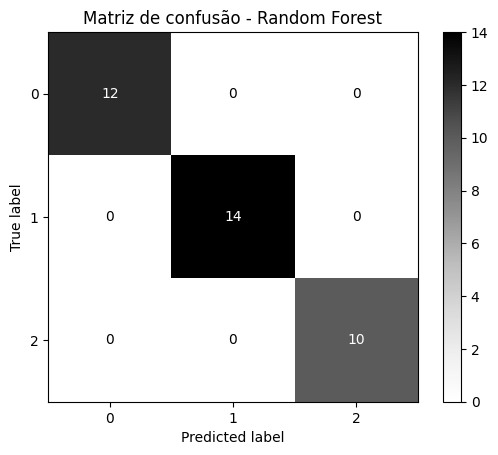

In [6]:
melhor_nome = max(resultados, key=resultados.get)
melhor = modelos[melhor_nome]
print("Melhor modelo no teste:", melhor_nome, "\n")
print(classification_report(y_teste, melhor.predict(X_teste)))

ConfusionMatrixDisplay.from_estimator(melhor, X_teste, y_teste, cmap="Greys")
plt.title(f"Matriz de confusão - {melhor_nome}")
plt.show()

## 7. Quais medidas mais importam? (Random Forest)

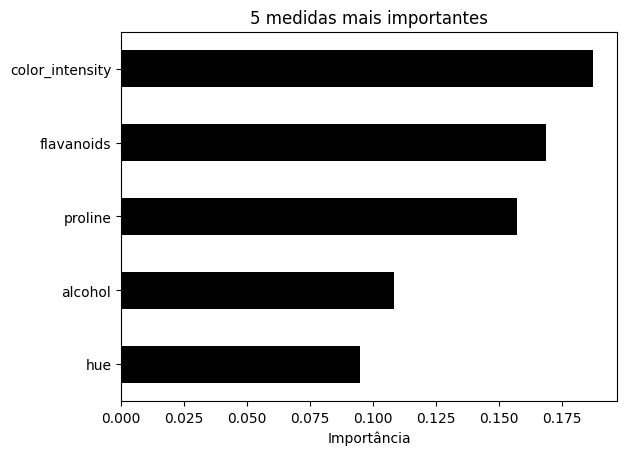

In [7]:
importancias = pd.Series(modelos["Random Forest"].feature_importances_, index=X.columns)
importancias.sort_values().tail(5).plot(kind="barh", color="black")
plt.title("5 medidas mais importantes")
plt.xlabel("Importância")
plt.show()

## 8. Conclusões

*(O Random Forest teve a melhor acurácia no teste (1,000), mas o conjunto de teste tem só 36 amostras. Na validação cruzada, a Regressão Logística foi um pouco melhor (0,983 contra 0,967), então os dois modelos têm desempenho muito parecido. As medidas que mais influenciaram foram a intensidade da cor, os flavonoides e a prolina.)*